# Deploying the retained GNN: contracts and distribution limits

This walkthrough loads the actual selected checkpoint and checks its graph input contract on **development records only**. It does not fit a model, select hyperparameters, read test predictions or rescore ELN/HTE. Per-reaction inputs, predictions and source identifiers are never displayed or saved. The final section derives a distribution diagnostic from already-published aggregate metrics; it introduces no new test outcome.

In [1]:
from pathlib import Path
import copy, hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch_geometric.data import Batch
from reaction_gnn.data import split_records
from reaction_gnn.graph import reaction_graph
from reaction_gnn.train import load_model, predict_record
ROOT = Path.cwd() if Path('src/reaction_gnn').exists() else Path.cwd().parent
FIGURES = ROOT / 'docs/figures'
FIGURES.mkdir(exist_ok=True)
torch.set_num_threads(2)
print('CPU checkpoint diagnostics; Python', platform.python_version())
print('No fitting, test scoring or per-reaction output.')

C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


CPU checkpoint diagnostics; Python 3.14.2
No fitting, test scoring or per-reaction output.


## Verify the artifact and restrict inputs

The retained checkpoint was refitted for 47 epochs after the three development studies were frozen. Its weights are local and ignored by Git. The processed ELN hash binds this diagnostic to the same real ORD cohort. We recreate the original scaffold split and concatenate only its train and validation partitions. These 610 rows were used for development/final refitting, so the checks below measure deployment mechanics rather than generalization.

In [2]:
release = json.loads((ROOT / 'docs/loss-v4/ELN-results.json').read_text())
checkpoint = ROOT / 'models/loss-v4/selected.pt'
assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == release['gnn_checkpoint_sha256']
raw = (ROOT / 'data/processed/reactions.json').read_bytes()
assert hashlib.sha256(raw).hexdigest() == 'cff11c38744ec83ef635d21464e6316690d59468ad823d234db7dbda54363eb0'
dataset = json.loads(raw)
splits = split_records(dataset['records'], seed=42)
development = splits['train'] + splits['validation']
assert len(development) == 610
assert not ({r['reaction_id'] for r in development} & {r['reaction_id'] for r in splits['test']})
# Labels and identifiers are removed before any prediction or graph construction.
inputs = [{'components': copy.deepcopy(r['components']),
           'temperature_c': r.get('temperature_c')} for r in development]
model = load_model(checkpoint)
print({'development_rows': len(inputs), 'feature_version': 1,
       'checkpoint_sha256': release['gnn_checkpoint_sha256'],
       'refit_epochs': release['final_refit_epochs']})

{'development_rows': 610, 'feature_version': 1, 'checkpoint_sha256': 'a23bf986ffaa53d6003dd6648f98141b697438c790c9bb8ebc60adab50ec2e97', 'refit_epochs': 47}


## What sizes and conditions does deployment need to support?

Build the real development graphs, retaining only aggregate sizes for display. Each component becomes a disconnected molecular graph; bidirectional edges represent bonds, and atom features include the declared reagent role. The retained model sees temperature and a missingness flag, but no quantities, products or laboratory procedures. These distributions describe the development envelope, not a calibrated out-of-distribution detector.

,atoms,directed_bond_edges,components
count,610.00,610.00,610.00
mean,105.21,214.46,5.99
std,26.45,59.35,0.10
min,56.00,104.00,5.00
25%,83.00,162.00,6.00
50%,97.00,198.00,6.00
75%,130.00,268.00,6.00
max,167.00,358.00,6.00


{'temperature_present': 610, 'temperature_missing': 0, 'development_temperature_min_c': 20.0, 'development_temperature_max_c': 200.0}


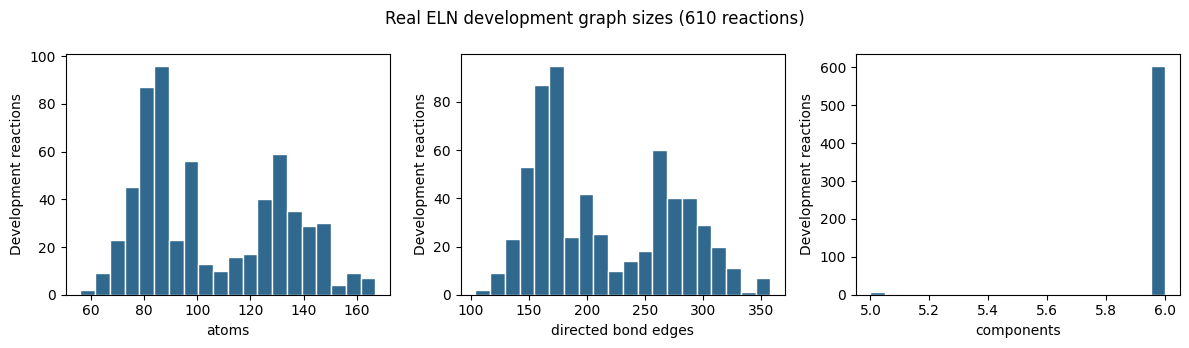

In [3]:
graphs = [reaction_graph(r) for r in inputs]
shape = pd.DataFrame({
    'atoms': [g.num_nodes for g in graphs],
    'directed_bond_edges': [g.num_edges for g in graphs],
    'components': [len(r['components']) for r in inputs],
})
assert all(g.x.shape[1] == 11 and g.edge_attr.shape[1] == 4 for g in graphs)
assert all(torch.isfinite(g.x).all() and torch.isfinite(g.conditions).all() for g in graphs)
display(shape.describe().round(2))
temperatures = np.array([r['temperature_c'] for r in inputs
                         if r['temperature_c'] is not None], dtype=float)
print({'temperature_present': len(temperatures),
       'temperature_missing': len(inputs) - len(temperatures),
       'development_temperature_min_c': float(temperatures.min()),
       'development_temperature_max_c': float(temperatures.max())})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column in zip(axes, shape.columns):
    ax.hist(shape[column], bins=20, color='#31688e', edgecolor='white')
    ax.set(xlabel=column.replace('_', ' '), ylabel='Development reactions')
fig.suptitle('Real ELN development graph sizes (610 reactions)')
fig.tight_layout()
fig.savefig(FIGURES / 'reaction_deployment_graph_sizes.png', dpi=150)
plt.show()

## Replay the production checkpoint and test invariances

Use the first 64 development inputs in their original order, without looking at outcomes. A graph model with symmetric pooling should tolerate component-order changes and batched inference. Adding unused outcome metadata should not change its result. These checks can expose deployment mistakes; they cannot demonstrate chemical accuracy. Only aggregate differences are retained.

In [4]:
sample = inputs[:64]
single = np.array([predict_record(model, r) for r in sample])
with torch.no_grad():
    batched = model(Batch.from_data_list([reaction_graph(r) for r in sample])).numpy() * 100
reordered = []
metadata_predictions = []
for record in sample:
    reversed_record = copy.deepcopy(record)
    reversed_record['components'].reverse()
    reordered.append(predict_record(model, reversed_record))
    decorated = copy.deepcopy(record)
    decorated['yield_percent'] = -999  # Metadata is deliberately ignored in inference.
    decorated['reaction_id'] = 'unused-for-model'
    metadata_predictions.append(predict_record(model, decorated))
checks = pd.DataFrame([
    {'check': 'Singleton versus batch', 'maximum_absolute_delta_pp': float(np.max(np.abs(single-batched)))},
    {'check': 'Component permutation', 'maximum_absolute_delta_pp': float(np.max(np.abs(single-reordered)))},
    {'check': 'Unused outcome/identifier metadata', 'maximum_absolute_delta_pp': float(np.max(np.abs(single-metadata_predictions)))},
])
assert np.isfinite(single).all() and ((single >= 0) & (single <= 100)).all()
assert (checks['maximum_absolute_delta_pp'] < 0.001).all()
display(checks)
print({'checkpoint_replay_rows': len(sample), 'finite_bounded_predictions': int(np.isfinite(single).sum()),
       'invariance_tolerance_pp': 0.001})

,check,maximum_absolute_delta_pp
0,Singleton versus batch,0.000007
1,Component permutation,0.000003
2,Unused outcome/identifier metadata,0.000000


{'checkpoint_replay_rows': 64, 'finite_bounded_predictions': 64, 'invariance_tolerance_pp': 0.001}


## Fail clearly on unsupported inputs

Empty molecular inputs, invalid roles and nonfinite temperatures must fail before producing an estimate. Null temperature is supported through the model's explicit missingness channel. These are contract checks using altered development inputs, not synthetic benchmark data or accuracy estimates.

In [5]:
invalid = []
empty = copy.deepcopy(sample[0]); empty['components'] = []
invalid.append(('empty components', empty))
role = copy.deepcopy(sample[0]); role['components'][0]['role'] = 99
invalid.append(('invalid role', role))
temp = copy.deepcopy(sample[0]); temp['temperature_c'] = float('nan')
invalid.append(('nonfinite temperature', temp))
rejections = []
for name, record in invalid:
    try:
        predict_record(model, record)
    except ValueError:
        rejections.append({'contract': name, 'rejected': True})
    else:
        raise AssertionError(f'Unsupported input was accepted: {name}')
display(pd.DataFrame(rejections))
missing = copy.deepcopy(sample[0]); missing['temperature_c'] = None
missing_prediction = predict_record(model, missing)
assert np.isfinite(missing_prediction) and 0 <= missing_prediction <= 100
print('Null-temperature inference is finite and bounded; this does not establish accuracy with missing conditions.')

,contract,rejected
0,empty components,True
1,invalid role,True
2,nonfinite temperature,True


Null-temperature inference is finite and bounded; this does not establish accuracy with missing conditions.


## Why the independent HTE R² is strongly negative

Use the stored aggregate RMSE and R² only. With the same cohort and population denominator, `target_sd = RMSE / sqrt(1 - R²)`. This recovers the target spread already implicit in the report; it does not reconstruct any reaction or prediction. HTE involves two documented substrate pairs and assay-yield measurements, unlike the broader ELN source. A smaller MAE than the transferred forest can coexist with very poor performance relative to the HTE cohort's own mean. That mean is an explanatory hindsight reference, not a deployable ELN-trained predictor.

,cohort,rows,GNN_RMSE_pp,target_population_sd_pp,squared_error_to_cohort_mean_ratio,recorded_R2
0,Observed ELN,130,29.2734,29.6775,0.9730,0.0270
1,Independent HTE,2048,25.8081,5.8984,19.1445,-18.1445


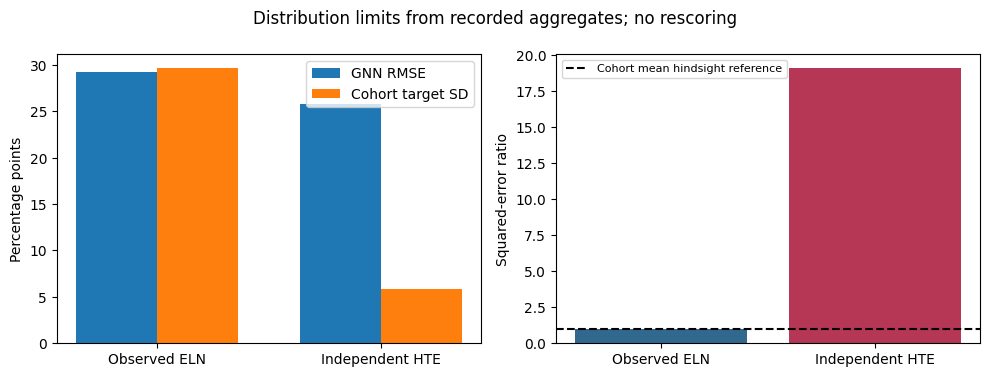

In [6]:
hte = json.loads((ROOT / 'docs/loss-v4/HTE-transfer-results.json').read_text())
rows = []
for cohort, report in [('Observed ELN', release['test_gnn']), ('Independent HTE', hte['gnn'])]:
    sd = report['rmse_percentage_points'] / np.sqrt(1-report['r2'])
    rows.append({'cohort': cohort, 'rows': report['rows'],
                 'GNN_RMSE_pp': report['rmse_percentage_points'],
                 'target_population_sd_pp': sd,
                 'squared_error_to_cohort_mean_ratio': 1-report['r2'],
                 'recorded_R2': report['r2']})
spread = pd.DataFrame(rows)
display(spread.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.arange(len(spread))
axes[0].bar(x-.18, spread['GNN_RMSE_pp'], .36, label='GNN RMSE')
axes[0].bar(x+.18, spread['target_population_sd_pp'], .36, label='Cohort target SD')
axes[0].set(xticks=x, xticklabels=spread['cohort'], ylabel='Percentage points')
axes[0].legend()
axes[1].bar(x, spread['squared_error_to_cohort_mean_ratio'], color=['#31688e','#b63655'])
axes[1].axhline(1, color='black', linestyle='--', label='Cohort mean hindsight reference')
axes[1].set(xticks=x, xticklabels=spread['cohort'], ylabel='Squared-error ratio')
axes[1].legend(fontsize=8)
fig.suptitle('Distribution limits from recorded aggregates; no rescoring')
fig.tight_layout()
fig.savefig(FIGURES / 'reaction_transfer_variance_diagnostic.png', dpi=150)
plt.show()

## Deployment conclusion

The checkpoint can be loaded, batched and replayed without output leakage or dependence on component order at the stated numerical tolerance. These mechanics do not repair the weak measured regression. The model does not return calibrated uncertainty, and bounded sigmoid predictions are not confidence intervals. New laboratory or prospective evaluation is needed before relying on an estimate. Keep the forest comparator and the negative HTE result visible; this notebook changes neither model selection nor the published scores.